# 15. Ajuste de parámetros de metaheurísticas

**Serie:** metaheurísticas from scratch · Bloque 05 — Evaluación y ajuste

Anterior: [14 · Medición de desempeño](14-medicion-de-desempeno.ipynb) ·
Siguiente: [16 · Hiperparámetros en ML con metaheurísticas](../06-aplicacion-ml/16-hiperparametros-ml-metaheuristicas.ipynb)

---

## Contenido

1. El problema de ajuste de parámetros: *tuning* vs. *control*, general vs. por instancia, hiperheurísticas
2. El objeto a ajustar: un recocido simulado parametrizable para TSP
3. Diseño de experimentos: factores, niveles, factorial completo
4. ANOVA: efectos principales e interacciones, supuestos y diagnóstico de residuales
5. Comparaciones por pares (Tukey HSD) y análisis de interacción
6. Fracciones factoriales ($2^{k-p}$) y *aliasing*
7. Hipercubo latino (LHS) y superficie de respuesta
8. *Racing* (F-race) e idea de irace en versión compacta
9. Control de parámetros: regla 1/5 de Rechenberg, SA con temperatura adaptativa, selección adaptativa de operadores
10. Selección y **validación en instancias no vistas**
11. Resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Qué vas a aprender**

- A formular el ajuste de parámetros como un problema de optimización **estocástico y costoso**, y a distinguir ajuste *offline* (antes de usar) de control *online* (durante la ejecución).
- A usar **diseño de experimentos** (factorial completo, fracciones, LHS) y **ANOVA** con `statsmodels` para entender qué parámetros importan y cómo interactúan, verificando los **supuestos** del ANOVA.
- A implementar una versión compacta de **irace** (*racing* con test de Friedman) y a compararla con el diseño factorial.
- A implementar **control adaptativo** (regla 1/5, temperatura adaptativa, selección de operadores).
- A **validar** una configuración ajustada en instancias que *no* se usaron para ajustarla y a medir el sobreajuste del ajuste.

**Prerrequisitos**: recocido simulado ([05](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb)),
métricas y pruebas estadísticas de [14](14-medicion-de-desempeno.ipynb) (gap, Wilcoxon, Friedman, Holm), nociones de ANOVA.

In [1]:
import time, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import qmc
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
ENT = 15_2024                                  # entropía maestra de la notebook
def rng_de(*clave):
    # generador independiente y reproducible para cada (experimento, instancia, configuración, repetición)
    return np.random.default_rng(np.random.SeedSequence(ENT, spawn_key=tuple(int(c) for c in clave)))

## 1. El problema de ajuste de parámetros

Toda metaheurística tiene **parámetros** (temperatura inicial, tasa de enfriamiento, tamaño de población, probabilidad de mutación, $\alpha,\beta,\rho$ en ACO, longitud de la lista tabú, ...) y **decisiones de diseño** categóricas (qué vecindario, qué operador de cruce). El desempeño depende fuertemente de ellos, y una comparación de algoritmos
(notebook [14](14-medicion-de-desempeno.ipynb)) es injusta si uno está bien ajustado y el otro no.

### Formulación

Sea $\Theta$ el espacio de configuraciones (mixto: continuo, entero, categórico, posiblemente con parámetros **condicionales**: la longitud de la lista tabú solo existe si el método usa memoria tabú), $\Pi$ una distribución de instancias y $c(\theta,\pi,\omega)$ el costo (p. ej. gap) de correr el algoritmo con configuración $\theta$ en la instancia $\pi$ con semilla $\omega$. El **ajuste offline** busca
$$\theta^\star=\arg\min_{\theta\in\Theta}\ \mathbb E_{\pi\sim\Pi,\ \omega}\bigl[c(\theta,\pi,\omega)\bigr],$$
con la esperanza estimada **solo mediante corridas** (cada evaluación del criterio es una corrida completa: ruidosa y cara). Es un problema de optimización estocástica de caja negra, en el que a su vez se puede usar una metaheurística (de ahí "meta-optimización").

### Taxonomía

| Criterio | Opción A | Opción B |
|---|---|---|
| **Cuándo** | **Ajuste** (*tuning*, offline): se fijan antes de ejecutar | **Control** (*online*): cambian durante la ejecución (adaptativo: según retroalimentación; autoadaptativo: viajan en la solución; determinista: según un calendario, p. ej. enfriamiento) |
| **Para quién** | **General**: una configuración para toda la clase de instancias | **Por instancia** (*instance-specific*): se ajusta o predice por instancia (p. ej. selección de algoritmo/portafolio) |
| **Cómo se elige** | Diseño de experimentos + estadística (ANOVA, RSM) | Optimización automática: **irace**, ParamILS, SMAC, ... |
| **Quién decide** | Un humano con un procedimiento | Una **hiperheurística**: un método de nivel superior que escoge o genera heurísticas (Burke et al., 2013) |

Sobre las **hiperheurísticas**: operan en el espacio de heurísticas en lugar del de soluciones. Se distinguen las que *seleccionan* heurísticas de bajo nivel (p. ej. el selector de operadores de la sección 9) de las que *generan* nuevas (programación genética). Son una forma de control online del *diseño* del algoritmo.

### Los costos del ajuste

Ajustar tiene un costo computacional y un **riesgo de sobreajuste**: una configuración óptima para las instancias de ajuste puede ser peor en instancias nuevas. Por eso: (i) **separar instancias de ajuste y de prueba**, (ii) usar presupuesto de ajuste comparable entre algoritmos que se comparan y (iii) reportar el desempeño en prueba, no el de ajuste.

## 2. El objeto a ajustar: un SA parametrizable para TSP

Ajustaremos un **recocido simulado** sobre TSP de $n=40$ ciudades con presupuesto fijo de $B=30\,000$ movimientos propuestos (evaluaciones delta $O(1)$). Los parámetros:

| Factor | Símbolo | Significado | Niveles (factorial completo) |
|---|---|---|---|
| Temperatura inicial | `t0f` | $T_0=\text{t0f}\cdot\bar d$, con $\bar d$ la distancia media entre ciudades | $0.01,\ 0.05,\ 0.25$ |
| Razón de enfriamiento | `ratio` | $T_f/T_0$; la temperatura baja geométricamente de $T_0$ a $T_f$ en exactamente $B$ pasos | $10^{-3},\ 10^{-2},\ 10^{-1}$ |
| Vecindario | `op` | `2opt` (reversión de segmento), `swap` (intercambio de dos ciudades), `insert` (reinserción de una ciudad) | 3 categorías |
| Inicio | `inicio` | tour aleatorio o vecino-más-cercano (solo se usa en la fracción factorial) | 2 categorías |

Parametrizar la temperatura **relativa a $\bar d$** y el final **relativo a $T_0$** hace los parámetros adimensionales y por tanto transferibles entre escalas de instancia: esa es una decisión de diseño que ya es, en sí misma, una forma de reducir la necesidad de ajuste.

La aceptación es la de Metropolis, $\Pr[\text{aceptar}]=\min\{1,e^{-\Delta/T}\}$. Con el esquema geométrico $T_k=T_0\,\text{ratio}^{k/B}$.

In [2]:
import time
from scipy.spatial.distance import cdist

def generar_tsp(n, tipo, rng):
    """Instancia euclídea 'uniforme' o 'agrupada'. Devuelve la matriz de distancias."""
    if tipo == "uniforme":
        pts = rng.random((n, 2))
    else:
        k = max(3, n // 10); c = rng.random((k, 2))
        pts = c[rng.integers(0, k, n)] + 0.04 * rng.standard_normal((n, 2))
    return cdist(pts, pts)

def largo(D, t):
    t = np.asarray(t); return float(D[t, np.roll(t, -1)].sum())

def vecino_mas_cercano(D, rng):
    n = len(D); s = int(rng.integers(n)); vis = np.zeros(n, bool); t = [s]; vis[s] = True
    for _ in range(n - 1):
        d = np.where(vis, np.inf, D[t[-1]]); j = int(d.argmin()); t.append(j); vis[j] = True
    return t

OPS = ["2opt", "swap", "insert"]

def sa_param(D, B, rng, t0f=0.05, ratio=1e-2, op="2opt", inicio="aleatorio",
             adaptativo=False, a0=0.3, a1=0.002, info=False):
    '''SA parametrizable para TSP con B movimientos propuestos (evaluaciones delta O(1)).
    - t0f: T0 = t0f * (distancia media entre ciudades); ratio = T_final / T0 (enfriamiento geométrico).
    - op: '2opt' | 'swap' | 'insert' | 'hiper' (selección adaptativa del operador, ver sección de control).
    - adaptativo: la temperatura se ajusta para seguir una tasa de aceptación objetivo que decae de a0 a a1.
    Devuelve (mejor_largo, mejor_tour, info_dict_o_None).'''
    n = len(D); Dl = D.tolist(); escala = D.sum() / (n * (n - 1))
    T0 = t0f * escala; Tf = T0 * ratio
    t = vecino_mas_cercano(D, rng) if inicio == "nn" else list(rng.permutation(n))
    L = largo(D, t); mejor, mejor_t = L, t[:]
    I = rng.integers(0, n, size=(B, 2)); U = rng.random(B); V = rng.random(B)
    T = T0; acept = 0; W = 100
    p = np.ones(3) / 3; score = np.full(3, 0.1); uso = np.zeros(3, int)
    fijo = OPS.index(op) if op in OPS else None
    hist_T, hist_acc = [], []
    for e in range(B):
        if e % W == 0:
            if adaptativo:
                if e > 0:
                    acc = acept / W; obj = a0 * (a1 / a0) ** (e / B)
                    T *= 0.9 if acc > obj else 1.1
                    hist_T.append(T); hist_acc.append(acc)
                acept = 0
            else:
                T = T0 * ratio ** (e / B)
                if info and e > 0: hist_T.append(T); hist_acc.append(acept / W)
                acept = 0
            if fijo is None and e > 0:                       # probability matching con piso 5 %
                q = score + 1e-9; p = 0.05 + 0.85 * q / q.sum(); p /= p.sum()
        k = fijo if fijo is not None else int(np.searchsorted(np.cumsum(p), V[e]))
        k = min(k, 2); uso[k] += 1
        i, j = int(I[e, 0]), int(I[e, 1]); delta = None
        if k == 0:
            if i > j: i, j = j, i
            if i != j and not (i == 0 and j == n - 1):
                a, b, c, d = t[i - 1], t[i], t[j], t[(j + 1) % n]
                delta = Dl[a][c] + Dl[b][d] - Dl[a][b] - Dl[c][d]
        elif k == 1:
            if i > j: i, j = j, i
            if i != j and not (i == 0 and j == n - 1):
                if j == i + 1:
                    a, x, y, c = t[i - 1], t[i], t[j], t[(j + 1) % n]
                    delta = Dl[a][y] + Dl[x][c] - Dl[a][x] - Dl[y][c]
                else:
                    a, x, b, c, y, d = t[i - 1], t[i], t[i + 1], t[j - 1], t[j], t[(j + 1) % n]
                    delta = (Dl[a][y] + Dl[y][b] + Dl[c][x] + Dl[x][d]
                             - Dl[a][x] - Dl[x][b] - Dl[c][y] - Dl[y][d])
        else:
            if j != i and j != (i - 1) % n:
                a, b, c = t[i - 1], t[i], t[(i + 1) % n]; u, v = t[j], t[(j + 1) % n]
                delta = Dl[a][c] - Dl[a][b] - Dl[b][c] + Dl[u][b] + Dl[b][v] - Dl[u][v]
        if delta is None:
            continue
        if delta < 0 or U[e] < np.exp(-delta / T):
            if k == 0: t[i:j + 1] = t[i:j + 1][::-1]
            elif k == 1: t[i], t[j] = t[j], t[i]
            else:
                nodo = t.pop(i); t.insert(j if j > i else j + 1, nodo)
            L += delta; acept += 1
            if L < mejor - 1e-12: mejor, mejor_t = L, t[:]
        if fijo is None:                                   # recompensa: 1 si el movimiento propuesto mejora
            score[k] = 0.99 * score[k] + 0.01 * (1.0 if delta < 0 else 0.0)
    inf = dict(T=np.array(hist_T), acc=np.array(hist_acc), uso=uso) if info else None
    return mejor, np.array(mejor_t), inf

In [3]:
# Verificación: para cada vecindario y cada modo, el largo acumulado por deltas coincide con el recomputado y el tour es permutación
D = generar_tsp(40, "uniforme", np.random.default_rng(1))
for op in OPS + ["hiper"]:
    for ad in (False, True):
        L, t, _ = sa_param(D, 20000, np.random.default_rng(0), op=op, adaptativo=ad)
        assert sorted(t.tolist()) == list(range(40)) and abs(largo(D, t) - L) < 1e-8, (op, ad)
print("OK: deltas de 2opt/swap/insert consistentes con la recomputación completa (incluye modos 'hiper' y adaptativo).")

# Instancias: ajuste (TRAIN), pool para racing (RACE), prueba no vista (TEST) y prueba de mayor tamaño (BIG)
def banco(tag, m, n):
    out = []
    for k in range(m):
        tipo = "uniforme" if k % 2 == 0 else "agrupada"
        out.append(dict(id=k, tipo=tipo, n=n, D=generar_tsp(n, tipo, np.random.default_rng([15, tag, k]))))
    return out
TRAIN, RACE, TEST, BIG = banco(1, 6, 40), banco(2, 24, 40), banco(3, 10, 40), banco(4, 6, 70)
B = 30_000
print({k: len(v) for k, v in dict(TRAIN=TRAIN, RACE=RACE, TEST=TEST, BIG=BIG).items()}, "| B =", B)

OK: deltas de 2opt/swap/insert consistentes con la recomputación completa (incluye modos 'hiper' y adaptativo).
{'TRAIN': 6, 'RACE': 24, 'TEST': 10, 'BIG': 6} | B = 30000


In [4]:
def correr(insts, cfgs, reps, tag, B=B):
    # Ejecuta todas las configuraciones x instancias x repeticiones. Devuelve DataFrame con el largo final.
    filas = []
    for ins in insts:
        for ci, cfg in enumerate(cfgs):
            for r in range(reps):
                L, t, _ = sa_param(ins["D"], B, rng_de(tag, ins["id"], ci, r), **cfg)
                filas.append(dict(inst=ins["id"], tipo=ins["tipo"], cfg=ci, rep=r, L=L, **cfg))
    return pd.DataFrame(filas)

# Mejor conocido por instancia: mínimo de corridas largas de SA y de todas las corridas de la notebook sobre esa instancia
def referencia(insts, tag, largo_B=300_000, runs=2):
    ref = {}
    for ins in insts:
        ref[ins["id"]] = min(sa_param(ins["D"], largo_B, rng_de(tag, 999, ins["id"], r), op="2opt", t0f=0.05, ratio=1e-3)[0] for r in range(runs))
    return ref

def con_gap(df, ref):
    # actualiza la referencia con lo observado (el gap nunca queda negativo) y agrega gap en %
    for i, m in df.groupby("inst").L.min().items(): ref[i] = min(ref[i], m)
    df = df.copy(); df["gap"] = 100 * (df.L - df.inst.map(ref)) / df.inst.map(ref); return df

t0 = time.perf_counter()
REF_TRAIN = referencia(TRAIN, 11)
print(f"referencias de entrenamiento en {time.perf_counter() - t0:.1f} s:", {k: round(v, 3) for k, v in REF_TRAIN.items()})

referencias de entrenamiento en 2.9 s: {0: 5.03, 1: 2.388, 2: 5.323, 3: 3.41, 4: 5.24, 5: 3.09}


## 3. Diseño de experimentos

### Conceptos

- **Factor**: un parámetro que se varía. **Nivel**: uno de sus valores. **Tratamiento** (celda): una combinación de niveles.
- **Respuesta** $y$: la métrica de calidad (aquí, transformada del gap).
- **Réplica**: repetir un tratamiento con semillas distintas para estimar el ruido.
- **Bloque**: factor de "molestia" que se controla pero no es de interés. Aquí la **instancia** es un bloque: dos instancias difieren en dificultad, y comparar celdas dentro de cada instancia elimina esa fuente de varianza.

### Diseños

- **Factorial completo** $\prod_i \ell_i$ tratamientos: estima todos los efectos principales e interacciones. Aquí $3\times3\times3=27$ tratamientos; crece exponencialmente con el número de factores.
- **Fracción factorial** $2^{k-p}$: con $k$ factores de dos niveles se corre solo $2^{-p}$ del total; se sacrifica información sobre interacciones de orden alto (se *confunden* o *alias* con efectos principales o de bajo orden). Sección 6.
- **Hipercubo latino (LHS)**: $m$ puntos tales que, proyectados en cada factor, caen uno en cada uno de $m$ estratos. Cubre factores **continuos** densamente con pocos puntos. Sección 7.
- **Diseños secuenciales / racing / irace**: se invierte el presupuesto en las configuraciones prometedoras. Sección 8.

### Factorial completo $3\times3\times3$ con bloques

Corremos los 27 tratamientos en las 6 instancias de ajuste, 8 réplicas por celda y bloque: $27\times6\times8=1296$ corridas.
Orden de ejecución y semillas no dependen de los resultados.

In [5]:
NIV_T0, NIV_RATIO = [0.01, 0.05, 0.25], [1e-3, 1e-2, 1e-1]
CFG_FULL = [dict(t0f=a, ratio=b, op=c) for a in NIV_T0 for b in NIV_RATIO for c in OPS]
t0 = time.perf_counter()
raw = correr(TRAIN, CFG_FULL, reps=8, tag=21)
fac = con_gap(raw, REF_TRAIN)
fac["y"] = np.log1p(fac.gap)                       # transformación de la respuesta (se justifica en la sección 4)
print(f"{len(fac)} corridas en {time.perf_counter() - t0:.1f} s")
print(fac.groupby("op").gap.mean().round(3).rename("gap medio (%) por vecindario").to_string())
print(fac.groupby("t0f").gap.mean().round(3).rename("gap medio (%) por t0f").to_string())
print(fac.groupby("ratio").gap.mean().round(3).rename("gap medio (%) por ratio").to_string())

1296 corridas en 36.7 s
op
2opt       2.370
insert    12.402
swap      37.937
t0f
0.01    25.979
0.05    17.568
0.25     9.162
ratio
0.001    19.530
0.010    17.969
0.100    15.210


## 4. ANOVA: efectos principales e interacciones

### Modelo

Con el factor de bloque (instancia $b$) y tres factores de tratamiento $A$ (t0f), $B$ (ratio), $C$ (vecindario):
$$y_{ijklr}=\mu+\beta_b+\alpha_i+\gamma_j+\delta_k+(\alpha\gamma)_{ij}+(\alpha\delta)_{ik}+(\gamma\delta)_{jk}+(\alpha\gamma\delta)_{ijk}+\varepsilon_{ijklr},\qquad \varepsilon\sim\mathcal N(0,\sigma^2).$$
La tabla ANOVA descompone la suma de cuadrados total en la de cada término y la **residual**; el contraste de cada término es
$F=\mathrm{MS}_{\text{término}}/\mathrm{MS}_{\text{res}}$. Con diseño **balanceado** (aquí, todas las celdas con el mismo número de datos) las sumas de cuadrados tipo I, II y III coinciden para los términos de interés, y la descomposición es ortogonal.

Reportamos también el **tamaño de efecto** $\eta_p^2=\mathrm{SS}_{\text{término}}/(\mathrm{SS}_{\text{término}}+\mathrm{SS}_{\text{res}})$: con $n=1296$, casi *todo* es "significativo", así que el $p$-valor por sí solo es poco informativo.

### Supuestos (y cómo se verifican)

1. **Independencia**: las corridas usan semillas independientes y la instancia está en el modelo como bloque. Se cumple por construcción del diseño.
2. **Normalidad de los residuales**: se inspecciona con un gráfico Q–Q y se complementa con Shapiro–Wilk (que con $n$ grande rechaza ante desviaciones ínfimas, así que *no* se usa como criterio único). El ANOVA balanceado es razonablemente robusto a desviaciones moderadas.
3. **Homocedasticidad** (varianza constante entre celdas): gráfico de residuales vs. ajustados y prueba de Levene.

El gap es no negativo y asimétrico, y su variabilidad crece con su media: típicamente se **transforma** la respuesta ($\log(1+\text{gap})$) para estabilizar la varianza. Verificamos con residuales *antes y después*.

Respuesta cruda (gap %):       {'asimetria_resid': 1.121, 'curtosis_exc': 4.59, 'Shapiro_W': 0.9185, 'Shapiro_p': 7.4e-26, 'Levene_p': 7.24e-48, 'razon_var_max_min': 55.63}
Respuesta log(1+gap):          {'asimetria_resid': -0.158, 'curtosis_exc': -0.007, 'Shapiro_W': 0.9969, 'Shapiro_p': 0.0114, 'Levene_p': 4.18e-11, 'razon_var_max_min': 4.64}


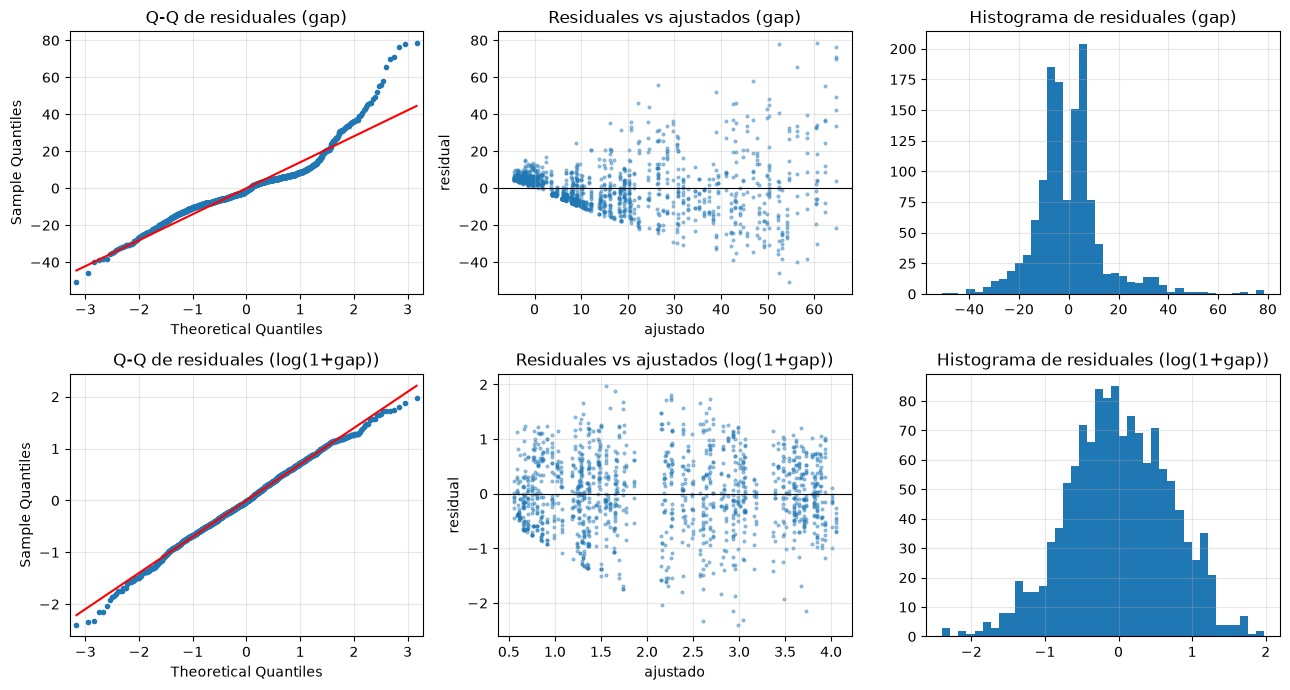

In [6]:
f_rhs = "C(inst) + C(t0f) * C(ratio) * C(op)"
m_raw = smf.ols("gap ~ " + f_rhs, data=fac).fit()
m_log = smf.ols("y ~ " + f_rhs, data=fac).fit()

def diag(m, df, resp):
    res = m.resid
    sw = stats.shapiro(res)
    grupos = [res[g.index].values for _, g in df.groupby(["t0f", "ratio", "op"])]        # residuales por celda de tratamiento
    lev = stats.levene(*grupos, center="median"); v = np.array([g.var(ddof=1) for g in grupos])
    return dict(asimetria_resid=round(float(stats.skew(res)), 3), curtosis_exc=round(float(stats.kurtosis(res)), 3),
                Shapiro_W=round(float(sw.statistic), 4), Shapiro_p=float(f"{sw.pvalue:.3g}"), Levene_p=float(f"{lev.pvalue:.3g}"),
                razon_var_max_min=round(float(v.max() / v.min()), 2))

print("Respuesta cruda (gap %):      ", diag(m_raw, fac, "gap"))
print("Respuesta log(1+gap):         ", diag(m_log, fac, "y"))

fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for fila, (m, nom) in enumerate([(m_raw, "gap"), (m_log, "log(1+gap)")]):
    sm.qqplot(m.resid, line="s", ax=axs[fila, 0], markersize=3); axs[fila, 0].set_title(f"Q-Q de residuales ({nom})")
    axs[fila, 1].scatter(m.fittedvalues, m.resid, s=4, alpha=.4); axs[fila, 1].axhline(0, color="k", lw=.8)
    axs[fila, 1].set_xlabel("ajustado"); axs[fila, 1].set_ylabel("residual"); axs[fila, 1].set_title(f"Residuales vs ajustados ({nom})")
    axs[fila, 2].hist(m.resid, bins=40); axs[fila, 2].set_title(f"Histograma de residuales ({nom})")
plt.tight_layout(); plt.show()

**Resultado del diagnóstico.** Compara las dos líneas impresas y los gráficos:

- Con la respuesta **cruda** los residuales son claramente asimétricos y de colas pesadas (asimetría y curtosis grandes, Q–Q curvado) y la razón entre la mayor y la menor varianza por celda es enorme: no se cumplen ni la normalidad ni la homocedasticidad.
- Tras $\log(1+\text{gap})$ la asimetría y el exceso de curtosis son cercanos a 0 y el Q–Q es casi una recta. Shapiro–Wilk aún puede rechazar (con 1296 datos detecta desviaciones diminutas), pero ya no hay una desviación de importancia práctica en la forma.
- La homocedasticidad **mejora mucho pero no es perfecta**: Levene sigue rechazando con esta muestra tan grande, aunque la razón de varianzas máxima/mínima quedó en un valor moderado. Como el diseño es **balanceado** (mismo número de datos por celda), el ANOVA es robusto a esa heterogeneidad moderada; como salvaguarda, la tabla siguiente incluye también el $p$-valor con **errores robustos HC3**.

In [7]:
# Tabla ANOVA (tipo II) sobre la respuesta transformada, con tamaño de efecto y comparación con errores robustos HC3
aov = anova_lm(m_log, typ=2)
aov["eta2_parcial"] = aov.sum_sq / (aov.sum_sq + aov.loc["Residual", "sum_sq"])
aov_rob = anova_lm(m_log, typ=2, robust="hc3")
aov["p_HC3"] = aov_rob["PR(>F)"]
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
tab = aov[["df", "sum_sq", "F", "PR(>F)", "p_HC3", "eta2_parcial"]].copy()
tab.index = [i.replace("C(", "").replace(")", "") for i in tab.index]
print(tab.to_string())
print(f"\nR^2 del modelo = {m_log.rsquared:.3f};  residual: gl = {int(m_log.df_resid)}, sigma = {np.sqrt(m_log.scale):.3f}")
print("Términos con eta2 parcial >= 0.01:", [i for i in tab.index if i != "Residual" and tab.loc[i, "eta2_parcial"] >= 0.01])

               df  sum_sq     F     PR(>F)     p_HC3  eta2_parcial
inst            5   6.838 2.733    0.01829  0.005799        0.0107
t0f             2   180.7 180.5   1.07e-69  5.99e-60        0.2222
ratio           2   6.972 6.968  0.0009786    0.0289        0.0109
op              2    1284  1283 5.419e-305         0          0.67
t0f:ratio       4   4.558 2.278      0.059   0.03448      0.007156
t0f:op          4   34.03    17  1.367e-13 1.562e-16       0.05106
ratio:op        4   5.712 2.854    0.02266  0.007774      0.008952
t0f:ratio:op    8   13.49 3.371  0.0007814 0.0002375       0.02089
Residual     1264   632.4   NaN        NaN       NaN           0.5

R^2 del modelo = 0.708;  residual: gl = 1264, sigma = 0.707
Términos con eta2 parcial >= 0.01: ['inst', 't0f', 'ratio', 'op', 't0f:op', 't0f:ratio:op']


**Cómo leer la tabla.**

- La fila `inst` (bloque) captura cuánto del error se debe a la dificultad de cada instancia: eliminarla del error residual **aumenta la potencia** de los contrastes de los factores.
- Los efectos principales dicen si cambiar un factor *en promedio* cambia la respuesta. Una **interacción** significativa dice que el efecto de un factor *depende del nivel de otro*, y entonces **los efectos principales no se pueden interpretar aisladamente** (p. ej. "el mejor `t0f` depende del vecindario").
- Compara `PR(>F)` con `p_HC3`: si coinciden en la conclusión, la heterocedasticidad residual no cambia lo que concluimos.
- Fíjate en $\eta_p^2$ para ordenar por **importancia práctica**, no por significancia.

El ANOVA responde "¿qué factores importan?", no "¿cuál es la mejor configuración?"; para eso están las comparaciones por pares y el análisis de interacción.

### 4.1 ¿Cambia el mejor tratamiento según la instancia? (ajuste general vs. por instancia)

Un supuesto implícito del ajuste *general* es que una sola configuración sirve a toda la clase de instancias. Esto se puede
contrastar con el modelo **ampliado** que permite que el efecto del vecindario dependa de la instancia
(`C(inst):C(op)`), comparado con el modelo sin esa interacción mediante un $F$ de modelos anidados.

In [8]:
m_ext = smf.ols("y ~ C(inst) * C(op) + C(t0f) * C(ratio) * C(op)", data=fac).fit()
cmp = anova_lm(m_log, m_ext)
print(cmp.to_string())
print(f"\nPrueba F de modelos anidados (interacción instancia x vecindario): F = {cmp['F'].iloc[1]:.3f}, p = {cmp['Pr(>F)'].iloc[1]:.3g}")

# mejor tratamiento por instancia (media de y sobre réplicas)
mejor_por_inst = (fac.groupby(["inst", "tipo", "t0f", "ratio", "op"]).y.mean().reset_index()
                  .sort_values("y").groupby("inst").first()[["tipo", "t0f", "ratio", "op", "y"]])
print("\nMejor tratamiento por instancia:"); print(mejor_por_inst.round(4).to_string())

   df_resid   ssr  df_diff  ss_diff     F    Pr(>F)
0      1264 632.4        0      NaN   NaN       NaN
1      1254 550.1       10    82.34 18.77 2.026e-32

Prueba F de modelos anidados (interacción instancia x vecindario): F = 18.772, p = 2.03e-32

Mejor tratamiento por instancia:
          tipo  t0f  ratio    op      y
inst                                   
0     uniforme 0.25    0.1  2opt  1.011
1     agrupada 0.05    0.1  2opt 0.1464
2     uniforme 0.25    0.1  2opt  0.559
3     agrupada 0.05    0.1  2opt 0.2218
4     uniforme 0.25   0.01  2opt 0.4962
5     agrupada 0.05    0.1  2opt 0.4499


**Lectura.** La prueba $F$ de modelos anidados contrasta si permitir que el efecto del vecindario dependa de la instancia mejora el ajuste. Un $p$ muy pequeño dice que **sí hay heterogeneidad entre instancias**, es decir, que una configuración única para todas es una simplificación. En la tabla de mejores tratamientos por instancia mira qué parámetros cambian y con qué tipo de instancia: eso es lo que justificaría el ajuste **por clase de instancia** (o por instancia con predicción de configuración), en lugar del ajuste general que aplicamos aquí.

## 5. Comparaciones por pares (Tukey HSD) y análisis de interacción

Tras el ANOVA, comparamos niveles de un factor con **Tukey HSD**, que controla la tasa de error *familiar* (no inflada por hacer varias comparaciones) con el cuantil del rango estudentizado. Es válida bajo normalidad y varianza homogénea (verificadas arriba) y **muestras independientes**. Para aplicarla respetando el bloque, comparamos las respuestas **centradas por instancia** $\tilde y=y-\bar y_{\text{inst}}$ (elimina el efecto de bloque). Esto es una aproximación: los grados de libertad residuales de `pairwise_tukeyhsd` no descuentan los parámetros del bloque, por lo que es ligeramente *anticonservadora*; con $n=1296$ la diferencia es mínima.

In [9]:
fac["yc"] = fac.y - fac.groupby("inst").y.transform("mean")
for factor in ["op", "t0f", "ratio"]:
    th = pairwise_tukeyhsd(fac.yc, fac[factor].astype(str), alpha=0.05)
    print(f"--- Tukey HSD para '{factor}' (respuesta log(1+gap), centrada por instancia)")
    print(pd.DataFrame(th._results_table.data[1:], columns=th._results_table.data[0]).to_string(index=False))

--- Tukey HSD para 'op' (respuesta log(1+gap), centrada por instancia)
group1 group2  meandiff  p-adj  lower  upper  reject
  2opt insert     1.133      0  1.001  1.264    True
  2opt   swap     2.436      0  2.304  2.567    True
insert   swap     1.303      0  1.172  1.435    True


--- Tukey HSD para 't0f' (respuesta log(1+gap), centrada por instancia)
group1 group2  meandiff  p-adj   lower   upper  reject
  0.01   0.05   -0.4936      0 -0.6912  -0.296    True
  0.01   0.25   -0.9136      0  -1.111  -0.716    True
  0.05   0.25     -0.42      0 -0.6176 -0.2224    True


--- Tukey HSD para 'ratio' (respuesta log(1+gap), centrada por instancia)
group1 group2  meandiff  p-adj   lower  upper  reject
 0.001   0.01   -0.0578 0.7879 -0.2639 0.1483   False
 0.001    0.1   -0.1762 0.1111 -0.3823 0.0299   False
  0.01    0.1   -0.1184 0.3687 -0.3245 0.0877   False


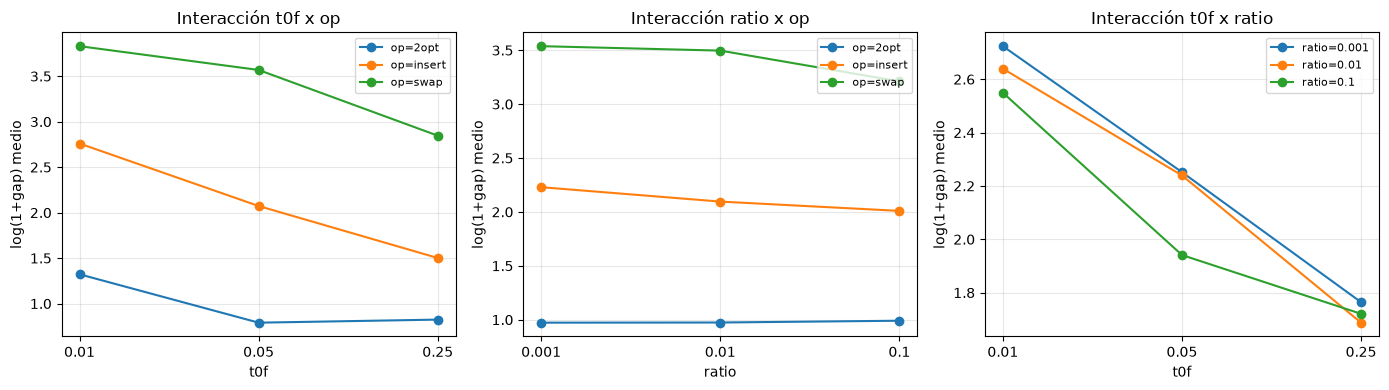

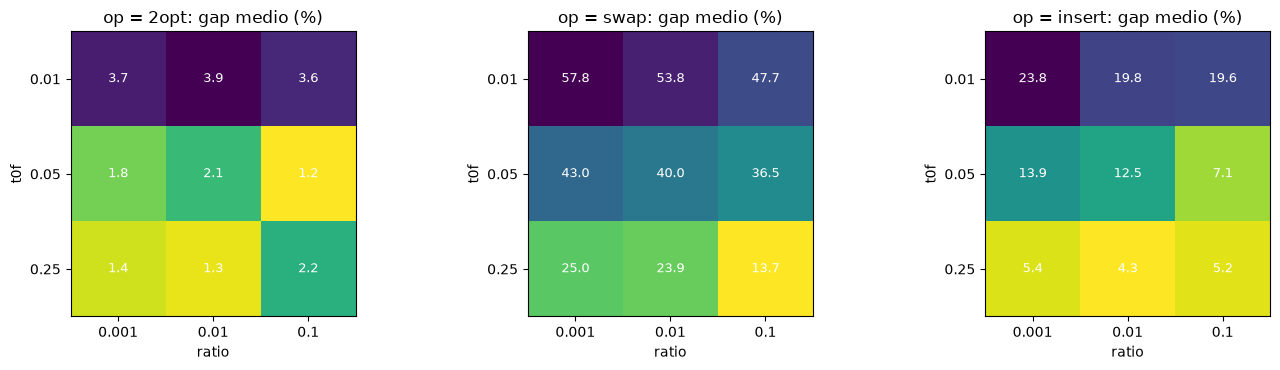

In [10]:
# Gráficos de interacción: media de y por nivel de un factor, una línea por nivel de otro. Líneas no paralelas = interacción
medias = fac.groupby(["t0f", "ratio", "op"]).y.mean().reset_index()
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, (xf, lf) in zip(axs, [("t0f", "op"), ("ratio", "op"), ("t0f", "ratio")]):
    piv = medias.groupby([xf, lf]).y.mean().unstack(lf)
    for col in piv.columns: ax.plot(range(len(piv.index)), piv[col].values, "o-", label=f"{lf}={col}")
    ax.set_xticks(range(len(piv.index))); ax.set_xticklabels([str(i) for i in piv.index])
    ax.set_xlabel(xf); ax.set_ylabel("log(1+gap) medio"); ax.set_title(f"Interacción {xf} x {lf}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Mapa de calor de t0f x ratio para cada vecindario (gap medio %)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, op in zip(axs, OPS):
    H = fac[fac.op == op].pivot_table(index="t0f", columns="ratio", values="gap")
    im = ax.imshow(H.values, cmap="viridis_r"); ax.set_xticks(range(3)); ax.set_xticklabels([f"{c:g}" for c in H.columns]); ax.set_yticks(range(3)); ax.set_yticklabels(H.index)
    for (i, j), v in np.ndenumerate(H.values): ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="w", fontsize=9)
    ax.set_title(f"op = {op}: gap medio (%)"); ax.set_xlabel("ratio"); ax.set_ylabel("t0f"); ax.grid(False)
plt.tight_layout(); plt.show()

In [11]:
# Selección: mejor tratamiento según la media de y; cuántos son estadísticamente indistinguibles del mejor
cel = fac.groupby(["t0f", "ratio", "op"]).agg(y=("y", "mean"), gap=("gap", "mean"), sd=("y", "std"), n=("y", "size")).reset_index()
cel["ee"] = cel.sd / np.sqrt(cel.n); cel = cel.sort_values("y").reset_index(drop=True)
print("Top-6 tratamientos del factorial completo:"); print(cel.head(6).round(4).to_string())
mejor = cel.iloc[0]; umbral = mejor.y + mejor.ee
# (Regla de 1 error estándar: se prefiere el tratamiento más simple/robusto dentro de 1 EE del mejor; aquí solo listamos los que caen dentro.)
print("\nTratamientos dentro de 1 error estándar del mejor:", int((cel.y <= umbral).sum()), "de", len(cel))
CFG_ANOVA = dict(t0f=float(mejor.t0f), ratio=float(mejor.ratio), op=str(mejor.op))
print("Configuración elegida por ANOVA/factorial:", CFG_ANOVA)

Top-6 tratamientos del factorial completo:
   t0f  ratio    op      y   gap     sd   n     ee
0 0.05    0.1  2opt 0.6426 1.243 0.5477  48  0.079
1 0.25   0.01  2opt 0.6827 1.328 0.5485  48 0.0792
2 0.25  0.001  2opt 0.7362  1.43 0.5412  48 0.0781
3 0.05  0.001  2opt 0.8343 1.803 0.6222  48 0.0898
4 0.05   0.01  2opt 0.8948 2.109 0.6919  48 0.0999
5 0.25    0.1  2opt  1.054 2.211 0.5025  48 0.0725

Tratamientos dentro de 1 error estándar del mejor: 2 de 27
Configuración elegida por ANOVA/factorial: {'t0f': 0.05, 'ratio': 0.1, 'op': '2opt'}


## 6. Fracciones factoriales y *aliasing*

Con $k=4$ factores de dos niveles hay $2^4=16$ tratamientos. Una **media fracción** $2^{4-1}$ corre solo 8, elegidos con el *generador* $D=ABC$ (equivalentemente, la **relación definitoria** $I=ABCD$, es decir, solo los tratamientos donde el producto de los niveles codificados $\pm1$ de $A,B,C,D$ es $+1$). El precio es el **aliasing**: cada efecto queda confundido con otro, que se obtiene multiplicando por la relación definitoria ($A\cdot ABCD=BCD$). En un diseño de **resolución IV** como este, los efectos principales se confunden con interacciones de **tres** factores (que suelen ser despreciables) y las de dos factores entre sí:
$$A\equiv BCD,\quad B\equiv ACD,\quad C\equiv ABD,\quad D\equiv ABC,\quad AB\equiv CD,\quad AC\equiv BD,\quad AD\equiv BC.$$
Estimamos el efecto de un término como $\hat e=\bar y_{+}-\bar y_{-}$; en la fracción, lo que se estima es la **suma** de los efectos alias:
$\hat e_{\text{fracción}}(A)=e(A)+e(BCD)$. Lo comprobamos numéricamente corriendo el factorial completo $2^4$ (16 tratamientos) y extrayendo de él la media fracción.

Factores: $A$ = `t0f` ($0.02$ / $0.25$), $B$ = `ratio` ($10^{-3}$ / $10^{-1}$), $C$ = vecindario (`2opt` / `insert`), $D$ = inicio (aleatorio / vecino más cercano).

In [12]:
niv = dict(A=(0.02, 0.25), B=(1e-3, 1e-1), C=("2opt", "insert"), D=("aleatorio", "nn"))
cod = list(itertools.product([-1, 1], repeat=4))                          # 16 tratamientos en niveles codificados
CFG2 = [dict(t0f=niv["A"][(a + 1) // 2], ratio=niv["B"][(b + 1) // 2], op=niv["C"][(c + 1) // 2], inicio=niv["D"][(d + 1) // 2]) for a, b, c, d in cod]
raw2 = correr(TRAIN, CFG2, reps=4, tag=22)
f2 = con_gap(raw2, REF_TRAIN); f2["y"] = np.log1p(f2.gap)
X = pd.DataFrame(cod, columns=list("ABCD")); X["y"] = f2.groupby("cfg").y.mean().values       # media por tratamiento (sobre instancias y réplicas)

terminos = [t for r in range(1, 5) for t in itertools.combinations("ABCD", r)]
def col(t, d): return np.prod([d[x] for x in t], axis=0)
def efecto(t, d):
    c = col(t, d); return d.y[c == 1].mean() - d.y[c == -1].mean()

completo = {"".join(t): efecto(t, X) for t in terminos}
media = X[(X.A * X.B * X.C * X.D) == 1]                                    # media fracción: ABCD = +1  (D = ABC)
alias = lambda s: "".join(sorted(set("ABCD") - set(s))) if len(s) < 4 else "I"
filas = []
for t in terminos:
    s = "".join(t); al = alias(s)
    if len(s) == 1 or (len(s) == 2 and s < al):                                                           # un renglón por par de alias
        est = efecto(t, media)
        assert abs(est - (completo[s] + completo.get(al, 0))) < 1e-9, (s, al)   # lo estimado = suma de efectos alias
        filas.append(dict(termino=s, alias=al, efecto_completo=completo[s], efecto_alias=completo.get(al, np.nan), estimado_en_fraccion=est))
print("Comprobación numérica superada: el estimado de la fracción = efecto(término) + efecto(alias) para todos los pares.\n")
print(pd.DataFrame(filas).round(4).to_string(index=False))

Comprobación numérica superada: el estimado de la fracción = efecto(término) + efecto(alias) para todos los pares.

termino alias  efecto_completo  efecto_alias  estimado_en_fraccion
      A   BCD          -0.1625        0.1568               -0.0057
      B   ACD           0.0265        0.2503                0.2768
      C   ABD             0.76        -0.039                 0.721
      D   ABC          -0.4237       -0.1047               -0.5284
     AB    CD           0.1482       -0.2976               -0.1493
     AC    BD          -0.1438        0.0418               -0.1019
     AD    BC           0.2784       -0.0321                0.2463


In [13]:
# ¿Qué efectos son significativos en el 2^4 completo? ANOVA con bloque instancia y los 4 factores codificados
f2["fA"] = f2.t0f.map({0.02: -1, 0.25: 1}); f2["fB"] = f2.ratio.map({1e-3: -1, 1e-1: 1})
f2["fC"] = f2.op.map({"2opt": -1, "insert": 1}); f2["fD"] = f2.inicio.map({"aleatorio": -1, "nn": 1})
m2 = smf.ols("y ~ C(inst) + C(fA) * C(fB) * C(fC) * C(fD)", data=f2).fit()
a2 = anova_lm(m2, typ=2); a2["eta2_parcial"] = a2.sum_sq / (a2.sum_sq + a2.loc["Residual", "sum_sq"])
a2.index = [i.replace("C(", "").replace(")", "").replace("fA", "A").replace("fB", "B").replace("fC", "C").replace("fD", "D") for i in a2.index]
print(a2.drop(index="Residual")[["df", "F", "PR(>F)", "eta2_parcial"]].sort_values("eta2_parcial", ascending=False).head(10).round(4).to_string())
print("\nResiduales del 2^4: Shapiro p =", f"{stats.shapiro(m2.resid).pvalue:.3g}", "| asimetría =", round(float(stats.skew(m2.resid)), 3))

       df     F  PR(>F)  eta2_parcial
C       1 114.7       0        0.2401
inst    5 8.832       0        0.1085
D       1 35.64       0        0.0894
C:D     1 17.58       0        0.0462
A:D     1 15.39  0.0001        0.0407
A:C:D   1 12.44  0.0005        0.0331
A       1 5.244  0.0226        0.0142
B:C:D   1  4.88  0.0278        0.0133
A:B     1 4.364  0.0374        0.0119
A:C     1 4.106  0.0435        0.0112

Residuales del 2^4: Shapiro p = 0.127 | asimetría = -0.032


**Lectura.** La tabla de arriba muestra el costo concreto del aliasing: cada estimado de la fracción mezcla dos efectos (comprobado con `assert`). La fracción da una buena estimación de un efecto principal **solo si su alias de tres factores es pequeño**: compara las columnas `efecto_completo` y `efecto_alias` renglón por renglón (cuando el alias es pequeño frente al efecto, no se pierde nada; cuando es comparable, la fracción habría engañado). El factorial completo del $2^4$ permite **verificar** ese supuesto, algo que en un estudio real con $2^{k-p}$ grande no se puede hacer (por eso se añaden réplicas del punto central y diseños secuenciales para "desaliasar"). Con muchos parámetros ($k\ge8$) las fracciones o los diseños de **cribado** (Plackett–Burman) son la manera de descartar rápidamente factores irrelevantes antes de un estudio detallado.

## 7. Hipercubo latino y superficie de respuesta

Un factorial en una malla de $\ell$ niveles prueba solo $\ell$ valores distintos de cada factor continuo. Un **hipercubo latino** de $m$ puntos en $[0,1]^d$ divide cada eje en $m$ estratos iguales y coloca **exactamente un punto por estrato y por eje**, de modo que cada factor se explora en $m$ valores distintos. Es el diseño estándar para muestrear $\Theta$ cuando el presupuesto es limitado y no se conoce qué factores importan (McKay et al., 1979).

LHS verificado: un punto por estrato en cada uno de los 3 ejes (m = 27 )


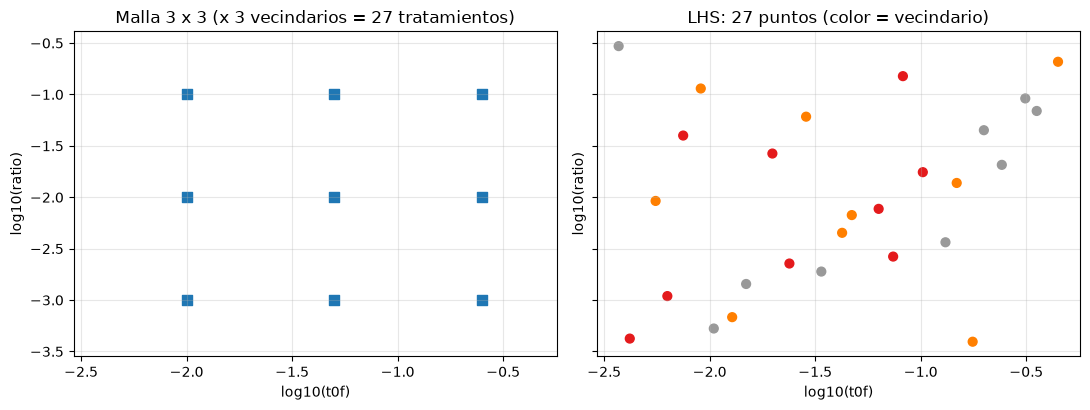

Valores distintos de t0f probados  -> malla: 3 | LHS: 27


In [14]:
m_lhs = 27
lhs = qmc.LatinHypercube(d=3, seed=7).random(m_lhs)
# propiedad definitoria: cada eje tiene exactamente un punto por estrato
for d_ in range(3): assert np.array_equal(np.sort(np.floor(lhs[:, d_] * m_lhs).astype(int)), np.arange(m_lhs))
print("LHS verificado: un punto por estrato en cada uno de los 3 ejes (m =", m_lhs, ")")

LO, HI = np.array([-2.5, -3.5]), np.array([-0.3, -0.5])              # rangos de log10(t0f) y log10(ratio)
pts = LO + lhs[:, :2] * (HI - LO)
grid = np.array([(np.log10(a), np.log10(b)) for a in NIV_T0 for b in NIV_RATIO])
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
axs[0].scatter(grid[:, 0], grid[:, 1], s=60, marker="s"); axs[0].set_title("Malla 3 x 3 (x 3 vecindarios = 27 tratamientos)")
axs[1].scatter(pts[:, 0], pts[:, 1], s=40, c=np.floor(lhs[:, 2] * 3), cmap="Set1"); axs[1].set_title("LHS: 27 puntos (color = vecindario)")
for ax in axs: ax.set_xlabel("log10(t0f)"); ax.set_ylabel("log10(ratio)")
plt.tight_layout(); plt.show()
print("Valores distintos de t0f probados  -> malla:", len(set(grid[:, 0])), "| LHS:", len(set(np.round(pts[:, 0], 9))))

### Superficie de respuesta cuadrática sobre un LHS

Con un LHS de 48 configuraciones de SA con vecindario `2opt` (en las dos variables continuas $x_1=\log_{10}t0f$, $x_2=\log_{10}\text{ratio}$) ajustamos por mínimos cuadrados un modelo cuadrático
$$\hat y=\beta_0+\beta_1x_1+\beta_2x_2+\beta_{11}x_1^2+\beta_{22}x_2^2+\beta_{12}x_1x_2$$
(*response surface methodology*, Box y Wilson, 1951), con el bloque instancia como efecto fijo, y buscamos su mínimo **dentro de la región experimental** (extrapolar un cuadrático fuera de los datos no es fiable). A diferencia del factorial, esto encuentra óptimos **entre** los niveles de la malla.

576 corridas en 16.3 s;  R^2 = 0.385
             coef  p (MCO)  p (HC3)
x1          1.448        0        0
x2          1.105        0        0
I(x1 ** 2)   0.39        0        0
I(x2 ** 2) 0.1645        0        0
x1:x2      0.2962        0        0
Residuales del RSM: Shapiro p = 3e-05 | Breusch-Pagan p = 1.6e-15
Óptimo del RSM en la región: {'t0f': 0.1339, 'ratio': 0.0027, 'op': '2opt'}


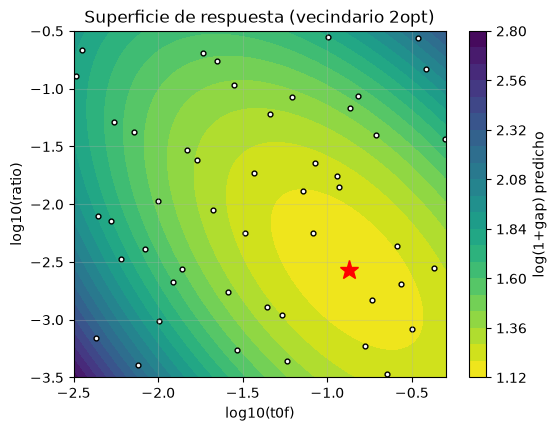

In [15]:
mm = 48
L2 = qmc.LatinHypercube(d=2, seed=11).random(mm); X2 = LO + L2 * (HI - LO)
CFG_LHS = [dict(t0f=10 ** x1, ratio=10 ** x2, op="2opt") for x1, x2 in X2]
t0 = time.perf_counter()
rl = con_gap(correr(TRAIN, CFG_LHS, reps=2, tag=23), REF_TRAIN); rl["y"] = np.log1p(rl.gap)
rl["x1"] = np.log10(rl.t0f); rl["x2"] = np.log10(rl.ratio)
rsm = smf.ols("y ~ C(inst) + x1 + x2 + I(x1**2) + I(x2**2) + x1:x2", data=rl).fit()
rsm_hc = smf.ols("y ~ C(inst) + x1 + x2 + I(x1**2) + I(x2**2) + x1:x2", data=rl).fit(cov_type="HC3")
print(f"{len(rl)} corridas en {time.perf_counter() - t0:.1f} s;  R^2 = {rsm.rsquared:.3f}")
coef = rsm.params.filter(regex="x"); pv = rsm.pvalues.filter(regex="x"); pvr = rsm_hc.pvalues.filter(regex="x")
print(pd.DataFrame({"coef": coef, "p (MCO)": pv, "p (HC3)": pvr}).round(4).to_string())
print("Residuales del RSM: Shapiro p =", f"{stats.shapiro(rsm.resid).pvalue:.3g}", "| Breusch-Pagan p =", f"{sm.stats.diagnostic.het_breuschpagan(rsm.resid, rsm.model.exog)[1]:.3g}")

# mínimo del cuadrático en una malla fina dentro del rango experimental (instancia de referencia = promedio de efectos de bloque)
g1, g2 = np.meshgrid(np.linspace(LO[0], HI[0], 120), np.linspace(LO[1], HI[1], 120))
# para predecir usamos la 1a instancia como bloque (el efecto de bloque solo desplaza la superficie)
pred = rsm.predict(pd.DataFrame(dict(inst=TRAIN[0]["id"], x1=g1.ravel(), x2=g2.ravel()))).values.reshape(g1.shape)
k = np.unravel_index(pred.argmin(), pred.shape); x1o, x2o = g1[k], g2[k]
CFG_RSM = dict(t0f=float(10 ** x1o), ratio=float(10 ** x2o), op="2opt")
print("Óptimo del RSM en la región:", {k_: round(v, 4) if isinstance(v, float) else v for k_, v in CFG_RSM.items()})
fig, ax = plt.subplots(figsize=(6, 4.5)); cs = ax.contourf(g1, g2, pred, 20, cmap="viridis_r"); plt.colorbar(cs, label="log(1+gap) predicho")
ax.scatter(X2[:, 0], X2[:, 1], c="w", s=12, edgecolor="k"); ax.plot(x1o, x2o, "r*", ms=14)
ax.set_xlabel("log10(t0f)"); ax.set_ylabel("log10(ratio)"); ax.set_title("Superficie de respuesta (vecindario 2opt)"); plt.show()

**Sobre el ajuste cuadrático.** Observa el $R^2$ (incluye el bloque instancia), la prueba de Breusch–Pagan (heterocedasticidad) y Shapiro sobre los residuales impresos: el modelo cuadrático es una **aproximación gruesa** de una superficie ruidosa y heterocedástica, por eso reportamos $p$-valores con errores robustos HC3 y usamos el óptimo del RSM solo como **candidato** que luego se valida en instancias no vistas (sección 10), no como verdad. Una mejora natural es modelar $\log$ de la respuesta por instancia o usar un modelo no paramétrico (procesos gaussianos), cf. SMAC.

## 8. *Racing* e idea de irace

Un factorial gasta el mismo presupuesto en configuraciones claramente malas que en las buenas. El **racing** (Maron y Moore, 1994; **F-race**, Birattari et al., 2002) evalúa todas las configuraciones **instancia por instancia** y, tras cada instancia (a partir de un mínimo), aplica un test estadístico para **descartar** las que son significativamente peores que la mejor. El presupuesto se concentra en las supervivientes.

**irace** (López-Ibáñez et al., 2016) añade un muestreo adaptativo: itera (muestrear configuraciones desde una distribución → *race* → reajustar la distribución alrededor de las *élites*). Nuestra versión compacta:

1. **Iteración 1**: 24 configuraciones muestreadas por LHS en el espacio mixto (2 parámetros continuos en escala log + 1 categórico). *Race* sobre instancias del pool de racing.
2. **Iteración 2**: las 3 mejores (*élites*) más 9 configuraciones nuevas muestreadas **alrededor de ellas** (gaussiana en escala log con desviación 0.25 y vecindario heredado con prob. 0.7). *Race* sobre instancias *nuevas*.
3. Se devuelve la élite con mejor rango medio.

### Test de eliminación (Conover, como en F-race)

En cada instancia se **rankean** las configuraciones vivas (menor largo = rango 1; el ranking hace el criterio independiente de la escala de la instancia). Con $b$ instancias y $k$ configuraciones vivas, $R_j$ la suma de rangos de $j$, $A_1=\sum_{i,j}R_{ij}^2$, $C_1=bk(k+1)^2/4$:
$$T_1=\frac{(k-1)\bigl(\sum_jR_j^2-bC_1\bigr)}{A_1-C_1},\qquad T_2=\frac{(b-1)\,T_1}{b(k-1)-T_1}\ \sim\ F_{k-1,(b-1)(k-1)}.$$
Si se rechaza $H_0$ (todas iguales), se descarta toda configuración $j$ con
$$|R_j-R_{\text{mejor}}|>t_{1-\alpha/2,(b-1)(k-1)}\sqrt{\frac{2\,(bA_1-\sum_jR_j^2)}{(b-1)(k-1)}}.$$
$T_1$ es el estadístico de Friedman con corrección de empates. Primero lo validamos contra `scipy`.

In [16]:
def friedman_conover(R):
    # R: matriz b x k de rangos por bloque (fila). Devuelve (T1, p_F, Rj, umbral_post_hoc)
    b, k = R.shape; Rj = R.sum(0); A1 = (R ** 2).sum(); C1 = b * k * (k + 1) ** 2 / 4
    T1 = (k - 1) * ((Rj ** 2).sum() - b * C1) / (A1 - C1)
    T2 = (b - 1) * T1 / (b * (k - 1) - T1)
    p = stats.f.sf(T2, k - 1, (b - 1) * (k - 1))
    umbral = stats.t.ppf(0.975, (b - 1) * (k - 1)) * np.sqrt(2 * (b * A1 - (Rj ** 2).sum()) / ((b - 1) * (k - 1)))
    return T1, p, Rj, umbral

# validación: T1 coincide con el chi2 de Friedman de scipy (sin y con empates)
rg = np.random.default_rng(0)
Y = rg.normal(size=(9, 5)) + np.arange(5) * 0.4
Y[:, 4] = Y[:, 3]                                                     # fuerza empates
Rk = np.apply_along_axis(stats.rankdata, 1, Y)
print("T1 =", round(friedman_conover(Rk)[0], 6), "| chi2 scipy =", round(stats.friedmanchisquare(*Y.T).statistic, 6))

T1 = 17.28655 | chi2 scipy = 17.28655


racing: 278 corridas en 8.8 s
  iteración 1: 24 candidatas, 12 instancias -> corridas 183 de 288 que gastaría el diseño completo (64 %)
  iteración 2: 12 candidatas, 12 instancias -> corridas 95 de 144 (66 %)
Élites finales (mejor primero), con rango medio:
   {'t0f': 0.5012, 'ratio': 0.0042, 'op': '2opt'} rango medio = 2.67
   {'t0f': 0.0807, 'ratio': 0.0417, 'op': '2opt'} rango medio = 2.75
   {'t0f': 0.3276, 'ratio': 0.0087, 'op': '2opt'} rango medio = 3.00
   {'t0f': 0.5012, 'ratio': 0.0084, 'op': '2opt'} rango medio = 3.25
   {'t0f': 0.0763, 'ratio': 0.1023, 'op': '2opt'} rango medio = 3.33


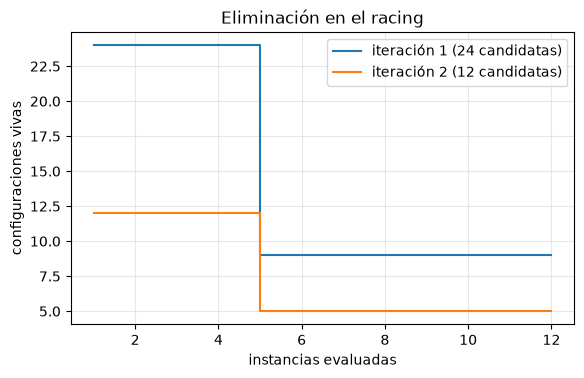

In [17]:
def muestrear(m, rng, elites=None, sigma=0.25):
    # configuraciones mixtas: LHS en iteración 1; gaussianas alrededor de élites después
    if elites is None:
        u = qmc.LatinHypercube(d=3, seed=int(rng.integers(1 << 30))).random(m)
        x = LO + u[:, :2] * (HI - LO); ops = [OPS[min(int(v * 3), 2)] for v in u[:, 2]]
    else:
        x, ops = [], []
        for _ in range(m):
            padre = elites[rng.integers(len(elites))]
            x.append(np.clip(np.log10([padre["t0f"], padre["ratio"]]) + sigma * rng.standard_normal(2), LO, HI))
            ops.append(padre["op"] if rng.random() < 0.7 else OPS[rng.integers(3)])
        x = np.array(x)
    return [dict(t0f=float(10 ** a), ratio=float(10 ** b), op=o) for (a, b), o in zip(x, ops)]

def carrera(cands, insts, tag, t_primer=5, alpha=0.05, min_viv=3):
    # Race con test de Conover. Cada instancia se evalúa UNA vez por configuración viva (semilla propia).
    k = len(cands); vivas = list(range(k)); Lmat = np.full((len(insts), k), np.nan); hist = []; corridas = 0
    for bi, ins in enumerate(insts):
        for ci in vivas:
            Lmat[bi, ci] = sa_param(ins["D"], B, rng_de(tag, ins["id"], ci, 0), **cands[ci])[0]; corridas += 1
        hist.append(len(vivas))
        if bi + 1 >= t_primer and len(vivas) > min_viv:
            R = np.apply_along_axis(stats.rankdata, 1, Lmat[:bi + 1][:, vivas])
            T1, p, Rj, umbral = friedman_conover(R)
            if p < alpha:
                mejor = Rj.min(); keep = [c for c, r in zip(vivas, Rj) if r - mejor <= umbral]
                if len(keep) < min_viv: keep = [vivas[i] for i in np.argsort(Rj)[:min_viv]]
                vivas = keep; hist[-1] = len(vivas)
    R = np.apply_along_axis(stats.rankdata, 1, Lmat[:, vivas]); orden = np.argsort(R.sum(0))
    return [vivas[i] for i in orden], R.sum(0)[orden] / len(insts), hist, corridas

rg = np.random.default_rng(31); t0 = time.perf_counter()
cands1 = muestrear(24, rg)
viv1, rangos1, hist1, runs1 = carrera(cands1, RACE[:12], tag=31)
elites = [cands1[i] for i in viv1[:3]]
cands2 = elites + muestrear(9, rg, elites=elites)
viv2, rangos2, hist2, runs2 = carrera(cands2, RACE[12:], tag=32)
print(f"racing: {runs1 + runs2} corridas en {time.perf_counter() - t0:.1f} s")
print(f"  iteración 1: 24 candidatas, 12 instancias -> corridas {runs1} de {24 * 12} que gastaría el diseño completo ({100 * runs1 / (24 * 12):.0f} %)")
print(f"  iteración 2: 12 candidatas, 12 instancias -> corridas {runs2} de {12 * 12} ({100 * runs2 / (12 * 12):.0f} %)")
CFG_IRACE = cands2[viv2[0]]
print("Élites finales (mejor primero), con rango medio:")
for i, r in zip(viv2, rangos2): print("  ", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in cands2[i].items()}, f"rango medio = {r:.2f}")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.step(range(1, 13), hist1, where="post", label="iteración 1 (24 candidatas)"); ax.step(range(1, 13), hist2, where="post", label="iteración 2 (12 candidatas)")
ax.set_xlabel("instancias evaluadas"); ax.set_ylabel("configuraciones vivas"); ax.set_title("Eliminación en el racing"); ax.legend(); plt.show()

**Qué nos dice el racing.** Dos efectos: (i) el ahorro de corridas respecto al diseño completo (impreso arriba) y (ii) la **nueva exploración** de la iteración 2 alrededor de las élites, que el factorial de rejilla fija no hace. Limitaciones de nuestra versión: no hay *soft restart*, ni distribución de muestreo adaptada por parámetro, ni manejo de condicionales, ni límite de presupuesto global; el irace real también reparte el número de instancias por iteración con una fórmula en función del presupuesto. Las pruebas con $\alpha=0.05$ sin corrección por iteraciones repetidas son deliberadamente laxas (el objetivo del racing es *descartar rápido*, no inferir).

## 9. Control de parámetros

El ajuste *offline* fija $\theta$ antes de correr. El **control** lo ajusta durante la ejecución con alguno de estos mecanismos (Eiben, Hinterding y Michalewicz, 1999):

| Mecanismo | Idea | Ejemplo |
|---|---|---|
| Determinista | $\theta=g(t)$ según un calendario | Enfriamiento geométrico del SA |
| **Adaptativo** | $\theta$ se actualiza con *retroalimentación* de la búsqueda | Regla 1/5; SA con tasa de aceptación objetivo |
| Autoadaptativo | $\theta$ forma parte del genoma y evoluciona | $\sigma$ evolucionando en una estrategia evolutiva |

Control **no** elimina el ajuste: traslada parámetros a *meta-parámetros* (la tasa objetivo, el tamaño de ventana), que por lo general son menos sensibles.

### 9.1 Regla 1/5 de Rechenberg en una $(1+1)$-ES

Una $(1+1)$-ES genera $x'=x+\sigma\,\mathcal N(0,I)$ y se queda con $x'$ si es mejor. La **probabilidad de éxito** $p_s$ de una mutación depende de $\sigma$: con $\sigma$ muy pequeño casi todo se acepta pero el avance por paso es minúsculo; con $\sigma$ muy grande casi nada mejora. El avance esperado se maximiza en un $\sigma$ intermedio; en el modelo de la esfera la tasa de éxito óptima es $\approx0.27$ y en el modelo del corredor $\approx0.18$, y Rechenberg (1973) propuso la regla heurística: *si $p_s>1/5$ aumentar $\sigma$; si $p_s<1/5$ disminuirlo*. Con la forma de Schwefel: cada $G$ iteraciones, $\sigma\leftarrow\sigma/c$ si $p_s>1/5$ y $\sigma\leftarrow\sigma\,c$ si $p_s<1/5$, con $c=0.82$.

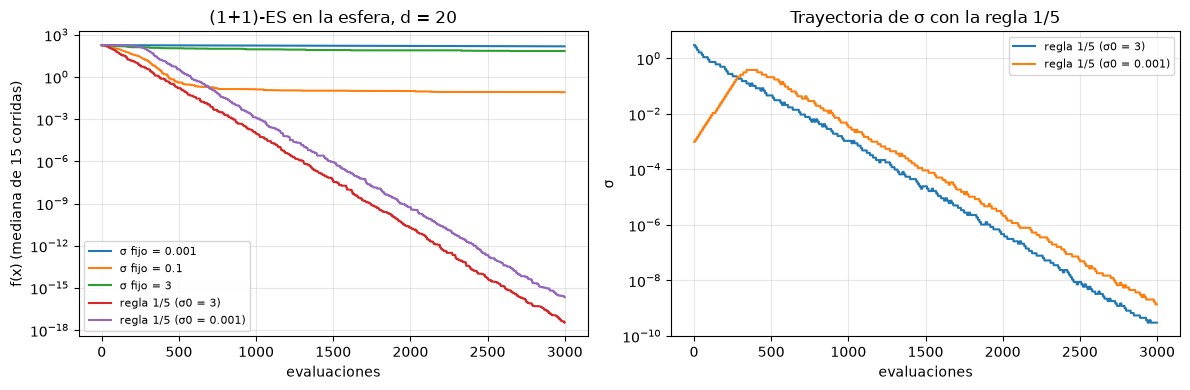

Mediana de f final tras 3000 evaluaciones: {'σ fijo = 0.001': 150.0, 'σ fijo = 0.1': 0.0817, 'σ fijo = 3': 69.1, 'regla 1/5 (σ0 = 3)': 3.41e-18, 'regla 1/5 (σ0 = 0.001)': 2.11e-16}


In [18]:
def es_1mas1(f, x0, sigma0, n_ev, rng, adaptar=True, G=10, c=0.82):
    # (1+1)-ES con regla 1/5 (adaptar=True) o sigma fijo. Devuelve trazas de f(x) y sigma por evaluación.
    x = x0.copy(); fx = f(x); sig = sigma0; exitos = 0; tf, ts = np.empty(n_ev), np.empty(n_ev)
    for e in range(n_ev):
        y = x + sig * rng.standard_normal(len(x)); fy = f(y)
        if fy < fx: x, fx = y, fy; exitos += 1
        tf[e], ts[e] = fx, sig
        if adaptar and (e + 1) % G == 0:
            ps = exitos / G; sig = sig / c if ps > 0.2 else (sig * c if ps < 0.2 else sig); exitos = 0
    return tf, ts

esfera = lambda x: float(np.dot(x, x))
d, NEV, R = 20, 3000, 15
x0 = np.full(d, 3.0)
resumen = {}
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for nombre, kw in [("σ fijo = 0.001", dict(sigma0=1e-3, adaptar=False)), ("σ fijo = 0.1", dict(sigma0=0.1, adaptar=False)),
                   ("σ fijo = 3", dict(sigma0=3.0, adaptar=False)), ("regla 1/5 (σ0 = 3)", dict(sigma0=3.0, adaptar=True)),
                   ("regla 1/5 (σ0 = 0.001)", dict(sigma0=1e-3, adaptar=True))]:
    runs = [es_1mas1(esfera, x0, n_ev=NEV, rng=rng_de(41, r), **kw) for r in range(R)]
    F = np.array([r[0] for r in runs]); S = np.array([r[1] for r in runs])
    axs[0].semilogy(np.median(F, axis=0), label=nombre)
    if kw["adaptar"]: axs[1].semilogy(np.median(S, axis=0), label=nombre)
    resumen[nombre] = np.median(F[:, -1])
axs[0].set_xlabel("evaluaciones"); axs[0].set_ylabel("f(x) (mediana de 15 corridas)"); axs[0].set_title(f"(1+1)-ES en la esfera, d = {d}"); axs[0].legend(fontsize=8)
axs[1].set_xlabel("evaluaciones"); axs[1].set_ylabel("σ"); axs[1].set_title("Trayectoria de σ con la regla 1/5"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Mediana de f final tras", NEV, "evaluaciones:", {k: float(f"{v:.3g}") for k, v in resumen.items()})

### 9.2 SA con temperatura adaptativa

El parámetro delicado del SA es la escala de la temperatura (depende de la instancia). Una alternativa es **controlar la tasa de aceptación** en lugar de la temperatura: cada ventana de $W=100$ movimientos se mide la tasa observada $\hat a$ y se compara con un **objetivo** $a(k)$ que decae geométricamente de $a_0=0.3$ a $a_1=0.002$ a lo largo de la corrida; si $\hat a>a(k)$ se enfría ($T\leftarrow0.9T$), si $\hat a<a(k)$ se calienta ($T\leftarrow1.1T$). Ya no hay que elegir `t0f` ni `ratio` (que dependen de la escala de la instancia) sino $a_0,a_1,W$ (que son **adimensionales** y menos sensibles). Mostramos las trayectorias de $T$ y de la aceptación para una instancia (**una sola corrida: ilustrativa, no evidencia**; la comparación estadística está en la sección 10).

geométrico (configuración por defecto)     largo final = 5.3053
adaptativo (tasa objetivo)                 largo final = 4.9702


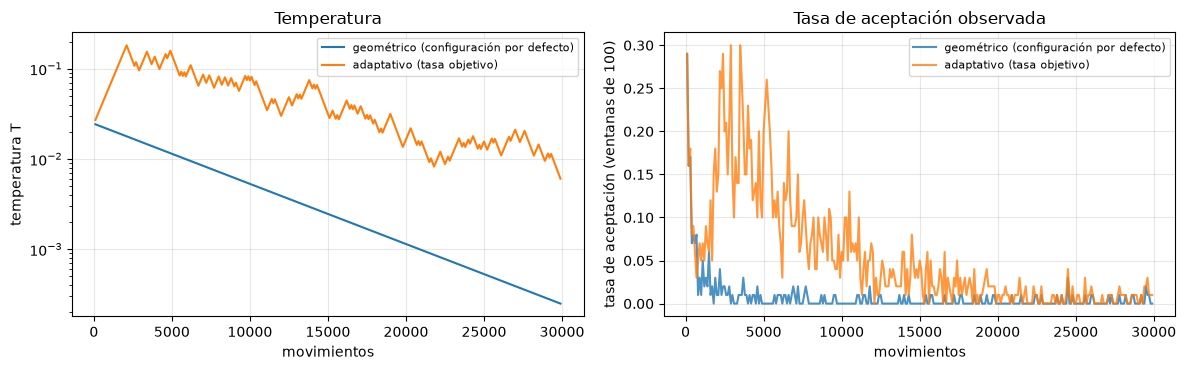

In [19]:
ins = TRAIN[0]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for nom, kw in [("geométrico (configuración por defecto)", dict(t0f=0.05, ratio=1e-2)), ("adaptativo (tasa objetivo)", dict(adaptativo=True))]:
    L, t, inf_ = sa_param(ins["D"], B, rng_de(42, 0), op="2opt", info=True, **kw)
    axs[0].semilogy(np.arange(1, len(inf_["T"]) + 1) * 100, inf_["T"], label=nom); axs[1].plot(np.arange(1, len(inf_["acc"]) + 1) * 100, inf_["acc"], label=nom, alpha=.8)
    print(f"{nom:42s} largo final = {L:.4f}")
axs[0].set_xlabel("movimientos"); axs[0].set_ylabel("temperatura T"); axs[0].set_title("Temperatura"); axs[0].legend(fontsize=8)
axs[1].set_xlabel("movimientos"); axs[1].set_ylabel("tasa de aceptación (ventanas de 100)"); axs[1].set_title("Tasa de aceptación observada"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 9.3 Selección adaptativa de operadores (una hiperheurística mínima)

En vez de fijar el vecindario (factor `op`), un **selector** escoge cada movimiento entre `2opt`, `swap` e `insert` con probabilidades proporcionales a una **puntuación** de éxito reciente (*probability matching*, Thierens, 2005): una media móvil exponencial $s_o\leftarrow0.99\,s_o+0.01\,r$, con recompensa $r=1$ si el movimiento propuesto mejora el tour. Para que ningún operador desaparezca, se reserva un piso de probabilidad del 5 % por operador. Este selector es una **hiperheurística de selección** sencilla: opera sobre el espacio de operadores. Se evalúa en la sección siguiente con los demás.

## 10. Selección y validación en instancias no vistas

Hasta aquí todas las decisiones usaron las instancias de ajuste (`TRAIN`) o del pool de racing (`RACE`). Ahora comparamos en **instancias nuevas** (10 de $n=40$, mismo tipo que el ajuste; 6 de $n=70$, **mayor tamaño**) las configuraciones:

| Nombre | Descripción |
|---|---|
| `defecto` | elección "razonable a ojo" sin ajustar: `t0f=0.05`, `ratio=1e-2`, `2opt` |
| `ANOVA` | mejor tratamiento del factorial completo |
| `RSM` | óptimo de la superficie de respuesta sobre LHS (solo `2opt`) |
| `irace-lite` | élite final del racing |
| `adaptativo` | SA con temperatura adaptativa, `2opt`, **sin** ajuste de T |
| `hiper` | selección adaptativa de operadores con el esquema de temperatura por defecto |

Mismo presupuesto $B$ para todos; el costo del *ajuste* no entra en la comparación (pero se discute abajo). Referencia por instancia: mejor de corridas largas de SA y de todas las corridas del experimento. La unidad de análisis es la **instancia** (mediana sobre repeticiones), como en la [notebook 14](14-medicion-de-desempeno.ipynb).

In [20]:
CFGS = {"defecto": dict(t0f=0.05, ratio=1e-2, op="2opt"), "ANOVA": CFG_ANOVA, "RSM": CFG_RSM, "irace-lite": CFG_IRACE,
        "adaptativo": dict(adaptativo=True, op="2opt"), "hiper": dict(t0f=0.05, ratio=1e-2, op="hiper")}
print({k: {a: (round(b, 4) if isinstance(b, float) else b) for a, b in v.items()} for k, v in CFGS.items()})

def evaluar(insts, tag, reps):
    filas = []
    for ins in insts:
        for ci, (nom, cfg) in enumerate(CFGS.items()):
            for r in range(reps):
                filas.append(dict(inst=ins["id"], tipo=ins["tipo"], cfg=nom, rep=r, L=sa_param(ins["D"], B, rng_de(tag, ins["id"], ci, r), **cfg)[0]))
    return pd.DataFrame(filas)

t0 = time.perf_counter()
REF_TEST = referencia(TEST, 51); REF_BIG = referencia(BIG, 52)
te = con_gap(evaluar(TEST, 61, reps=10), REF_TEST); bg = con_gap(evaluar(BIG, 62, reps=8), REF_BIG)
print(f"evaluación en instancias no vistas: {time.perf_counter() - t0:.1f} s  ({len(te)} + {len(bg)} corridas)")
# desempeño en las instancias de ajuste, para medir el sobreajuste del procedimiento de ajuste
tr = con_gap(evaluar(TRAIN, 63, reps=10), REF_TRAIN)
orden = list(CFGS)
res = pd.DataFrame({"gap medio TRAIN (%)": tr.groupby("cfg").gap.mean(), "gap medio TEST n=40 (%)": te.groupby("cfg").gap.mean(),
                    "gap medio BIG n=70 (%)": bg.groupby("cfg").gap.mean()}).loc[orden]
print(res.round(3).to_string())
mej = pd.DataFrame({"mejora vs defecto TRAIN (pp)": res["gap medio TRAIN (%)"]["defecto"] - res["gap medio TRAIN (%)"],
                    "mejora vs defecto TEST (pp)": res["gap medio TEST n=40 (%)"]["defecto"] - res["gap medio TEST n=40 (%)"],
                    "mejora vs defecto BIG (pp)": res["gap medio BIG n=70 (%)"]["defecto"] - res["gap medio BIG n=70 (%)"]}).loc[orden[1:]]
print("\nMejora respecto al defecto (puntos porcentuales de gap; controla la dificultad propia de cada conjunto de instancias):")
print(mej.round(3).to_string())

{'defecto': {'t0f': 0.05, 'ratio': 0.01, 'op': '2opt'}, 'ANOVA': {'t0f': 0.05, 'ratio': 0.1, 'op': '2opt'}, 'RSM': {'t0f': 0.1339, 'ratio': 0.0027, 'op': '2opt'}, 'irace-lite': {'t0f': 0.5012, 'ratio': 0.0042, 'op': '2opt'}, 'adaptativo': {'adaptativo': True, 'op': '2opt'}, 'hiper': {'t0f': 0.05, 'ratio': 0.01, 'op': 'hiper'}}


evaluación en instancias no vistas: 42.0 s  (600 + 288 corridas)


            gap medio TRAIN (%)  gap medio TEST n=40 (%)  gap medio BIG n=70 (%)
cfg                                                                             
defecto                   2.438                    2.521                   4.743
ANOVA                     1.279                    1.907                   3.719
RSM                       1.419                    1.648                   3.663
irace-lite                 1.24                    1.734                   2.791
adaptativo                1.103                    1.345                   3.788
hiper                     1.303                    1.711                   3.485

Mejora respecto al defecto (puntos porcentuales de gap; controla la dificultad propia de cada conjunto de instancias):
            mejora vs defecto TRAIN (pp)  mejora vs defecto TEST (pp)  mejora vs defecto BIG (pp)
cfg                                                                                              
ANOVA                              1

In [21]:
def comparar(dfx, nombre):
    M = dfx.pivot_table(index="inst", columns="cfg", values="gap", aggfunc="median")[orden]
    N, k = M.shape
    chi2, p = stats.friedmanchisquare(*[M[c].values for c in orden])
    print(f"== {nombre}: N = {N} instancias | Friedman chi2 = {chi2:.2f}, p = {p:.3g} | rangos medios: " + ", ".join(f"{c}={v:.2f}" for c, v in M.rank(axis=1).mean().items()))
    filas = []
    for c in orden[1:]:
        d = M[c].values - M["defecto"].values
        w = stats.wilcoxon(M[c].values, M["defecto"].values)
        r = stats.rankdata(np.abs(d[d != 0])); sg = np.sign(d[d != 0]); rb = (r[sg > 0].sum() - r[sg < 0].sum()) / r.sum()
        filas.append(dict(config=c, dif_mediana_gap_pp=np.median(d), p_wilcoxon=w.pvalue, r_biserial=rb, mejor_que_defecto_en=f"{int((d < 0).sum())}/{N}"))
    t = pd.DataFrame(filas); t["p_Holm"] = multipletests(t.p_wilcoxon, method="holm")[1]
    print(t.round(4).to_string(index=False)); print("(dif < 0 y r_biserial < 0 = mejor que el defecto)\n")
    return M

M_te = comparar(te, "TEST (n=40, no vistas)"); M_bg = comparar(bg, "BIG (n=70, no vistas)")

== TEST (n=40, no vistas): N = 10 instancias | Friedman chi2 = 7.43, p = 0.191 | rangos medios: defecto=4.80, ANOVA=3.40, RSM=3.50, irace-lite=3.60, adaptativo=3.00, hiper=2.70
    config  dif_mediana_gap_pp  p_wilcoxon  r_biserial mejor_que_defecto_en  p_Holm
     ANOVA             -0.3697      0.0645     -0.6727                 7/10  0.1934
       RSM             -0.6485       0.084     -0.6364                 6/10  0.1934
irace-lite             -0.4803       0.084     -0.6364                 8/10  0.1934
adaptativo             -0.8604      0.0273     -0.7818                 8/10  0.1094
     hiper             -0.8157      0.0137     -0.8545                 9/10  0.0684
(dif < 0 y r_biserial < 0 = mejor que el defecto)

== BIG (n=70, no vistas): N = 6 instancias | Friedman chi2 = 13.62, p = 0.0182 | rangos medios: defecto=5.50, ANOVA=3.17, RSM=3.50, irace-lite=2.17, adaptativo=4.33, hiper=2.33
    config  dif_mediana_gap_pp  p_wilcoxon  r_biserial mejor_que_defecto_en  p_Holm
     AN

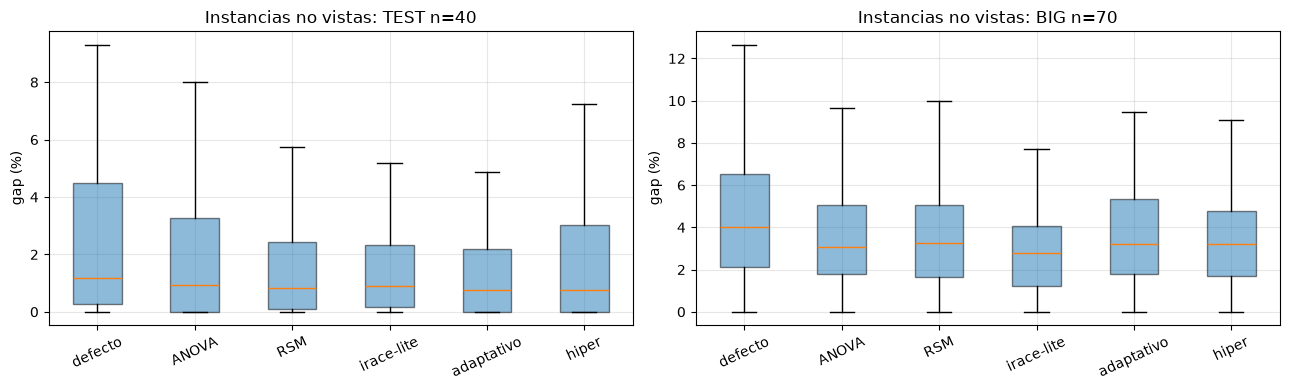

Fracción de movimientos por operador elegida por el selector (2opt, swap, insert):
  uniforme-0   [0.478 0.248 0.275]
  agrupada-1   [0.459 0.231 0.31 ]
  uniforme-2   [0.262 0.371 0.367]
  agrupada-3   [0.428 0.22  0.352]


In [22]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, dfx, nom in zip(axs, [te, bg], ["TEST n=40", "BIG n=70"]):
    bp = ax.boxplot([dfx[dfx.cfg == c].gap.values for c in orden], tick_labels=orden, patch_artist=True, showfliers=False)
    for p_ in bp["boxes"]: p_.set_alpha(.5)
    ax.set_ylabel("gap (%)"); ax.set_title(f"Instancias no vistas: {nom}"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

# uso de operadores por el selector adaptativo, por tipo de instancia
uso = {}
for ins in TEST[:4]:
    _, _, inf_ = sa_param(ins["D"], B, rng_de(64, ins["id"]), t0f=0.05, ratio=1e-2, op="hiper", info=True)
    uso[f"{ins['tipo']}-{ins['id']}"] = (inf_["uso"] / inf_["uso"].sum()).round(3)
print("Fracción de movimientos por operador elegida por el selector (2opt, swap, insert):")
for k_, v in uso.items(): print(f"  {k_:12s}", v)

**Cómo interpretar la validación.**

- **Comparar gaps absolutos entre conjuntos de instancias confunde la dificultad de cada conjunto** (y la calidad de su referencia) con el efecto de la configuración. Por eso la tabla de *mejora respecto al defecto* es la comparación razonable: una configuración ajustada rinde mejor en las instancias donde se eligió (optimismo: se escogió el mejor de muchas configuraciones ruidosas sobre ellas) que en las nuevas. Con solo 6 instancias de ajuste **no se puede separar** ese optimismo del ruido ni de las diferencias de dificultad; observa si la mejora cae de `TRAIN` a `TEST` y si lo hace también en las configuraciones que *no* se ajustaron con `TRAIN` (`adaptativo`, `hiper`), que sirven de grupo de control.
- **Potencia estadística**: con $N=10$ y $N=6$ instancias, Wilcoxon exacto con corrección de Holm es muy poco potente (con $N=6$ el menor $p$ bilateral posible es $2/64=0.031$ **antes** de corregir, así que ninguna comparación puede ser significativa tras Holm con 5 comparaciones). Mira los tamaños de efecto ($r_{rb}$) y el número de instancias en que cada configuración supera al defecto, y no solo si $p<0.05$. Un estudio serio de ajuste necesita más instancias de prueba.
- `BIG` es una prueba de **transferencia**: ¿se mantiene la ventaja de un ajuste hecho con $n=40$ cuando $n=70$ y el presupuesto es el mismo? Aquí el mismo $B$ da *menos movimientos por ciudad*, así que parte de la diferencia viene de la restricción de presupuesto, no solo de la configuración. Es un ejemplo de por qué el ajuste debe hacerse **para la clase de instancias y presupuesto de uso**.
- La prueba de Wilcoxon se hace a nivel de **instancia** con corrección de Holm (5 comparaciones contra el defecto) y se acompaña de $r_{rb}$, igual que en la notebook 14.
- El **costo de ajuste** no es gratis: el factorial usó 1296 corridas, el LHS 576 y el racing una fracción (impresa en la sección 8) de lo que habría costado un diseño completo equivalente. Debe amortizarse en el uso del algoritmo.

## Ventajas y limitaciones

| Enfoque | Ventajas | Limitaciones |
|---|---|---|
| Factorial completo + ANOVA | Entiende **qué** importa y cómo interactúa; inferencia formal | Crece exponencialmente; solo niveles discretos; supuestos que verificar |
| Fracción factorial | Pocos tratamientos; ideal para cribado | Aliasing; asume interacciones altas despreciables |
| LHS + RSM | Cubre factores continuos; encuentra óptimos entre niveles | El modelo cuadrático puede ser inadecuado; extrapolación peligrosa |
| Racing / irace | Eficiente: descarta rápido; maneja espacios mixtos y muchos parámetros | Menos interpretable; elimina por rangos, no explica *por qué*; sensible a la distribución de instancias |
| Control adaptativo | Se adapta a la instancia durante la corrida; menos sensible | Introduce meta-parámetros; la regla puede ser inestable |
| Hiperheurísticas | Automatizan el diseño del algoritmo | Más complejidad; la recompensa debe estar bien diseñada |

## Resumen

- Ajustar parámetros es un problema de optimización **estocástica**; se **valida** siempre en instancias no vistas.
- El diseño factorial con **ANOVA** (bloque = instancia) revela efectos principales e interacciones; hay que **verificar los supuestos** con los residuales y transformar la respuesta cuando haga falta.
- **Tukey HSD** controla el error familiar en las comparaciones por pares; las **fracciones factoriales** abaratan el cribado a cambio de aliasing explícito.
- **LHS** y **superficies de respuesta** cubren espacios continuos; **racing/irace** concentra el presupuesto en las candidatas buenas.
- El **control** adaptativo (regla 1/5, tasa de aceptación objetivo, selección de operadores) mueve la decisión al tiempo de ejecución, a cambio de meta-parámetros más estables.

## Ejercicios propuestos

1. Repite el ANOVA añadiendo el factor `inicio` (aleatorio/NN) en el diseño completo $3\times3\times3\times2$. ¿Aparece alguna interacción con el vecindario?
2. Cambia el presupuesto $B$ a 100 000 y repite el factorial. ¿Se mantiene el mejor tratamiento? (**El ajuste depende del presupuesto**.)
3. Ajusta un **ILS** (notebook [03](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb)) con los mismos métodos (factores: fuerza de perturbación, criterio de aceptación, búsqueda local). Compara el $\eta_p^2$ de sus factores con los del SA.
4. Replica el estudio para un **QAP** con matrices aleatorias de flujo y distancia ($n=15$): usa un SA con intercambio de dos ubicaciones, un factorial sobre temperatura y enfriamiento, y bloquea por instancia.
5. Modifica `carrera` para usar **Wilcoxon pareado con Holm** en lugar del test de Conover y compara el número de corridas gastadas y la configuración final.
6. Implementa *soft restart* en el irace compacto: tras la iteración 2, reinicia la distribución si las élites son demasiado parecidas (distancia en espacio log pequeña).
7. Mide el **sobreajuste del racing**: repite el procedimiento con 5 semillas distintas y calcula la dispersión del gap de la configuración final en `TEST`.

## Referencias

- Montgomery, D. C. (2017). *Design and Analysis of Experiments* (9.ª ed.). Wiley.
- Box, G. E. P., Hunter, J. S., Hunter, W. G. (2005). *Statistics for Experimenters* (2.ª ed.). Wiley.
- Box, G. E. P., Wilson, K. B. (1951). *On the experimental attainment of optimum conditions*. Journal of the Royal Statistical Society B, 13(1), 1-45.
- McKay, M. D., Beckman, R. J., Conover, W. J. (1979). *A comparison of three methods for selecting values of input variables in the analysis of output from a computer code*. Technometrics, 21(2), 239-245.
- Tukey, J. W. (1949). *Comparing individual means in the analysis of variance*. Biometrics, 5(2), 99-114.
- Conover, W. J. (1999). *Practical Nonparametric Statistics* (3.ª ed.). Wiley.
- Maron, O., Moore, A. W. (1994). *Hoeffding races: accelerating model selection search for classification and function approximation*. NIPS 6.
- Birattari, M., Stützle, T., Paquete, L., Varrentrapp, K. (2002). *A racing algorithm for configuring metaheuristics*. GECCO 2002.
- López-Ibáñez, M., Dubois-Lacoste, J., Pérez Cáceres, L., Birattari, M., Stützle, T. (2016). *The irace package: Iterated racing for automatic algorithm configuration*. Operations Research Perspectives, 3, 43-58.
- Eiben, Á. E., Hinterding, R., Michalewicz, Z. (1999). *Parameter control in evolutionary algorithms*. IEEE Transactions on Evolutionary Computation, 3(2), 124-141.
- Rechenberg, I. (1973). *Evolutionsstrategie: Optimierung technischer Systeme nach Prinzipien der biologischen Evolution*. Frommann-Holzboog.
- Burke, E. K., Gendreau, M., Hyde, M., Kendall, G., Ochoa, G., Özcan, E., Qu, R. (2013). *Hyper-heuristics: a survey of the state of the art*. Journal of the Operational Research Society, 64(12), 1695-1724.
- Thierens, D. (2005). *An adaptive pursuit strategy for allocating operator probabilities*. GECCO 2005.
- Hutter, F., Hoos, H. H., Leyton-Brown, K., Stützle, T. (2009). *ParamILS: an automatic algorithm configuration framework*. Journal of Artificial Intelligence Research, 36, 267-306.